# Geometría computacional · Envolventes y barridos

Algoritmos sobre conjuntos de puntos y segmentos: la envolvente convexa (Graham y la cadena monótona de Andrew, comprobadas entre sí, con `scipy.spatial.ConvexHull` y con fuerza bruta), el punto en un polígono convexo por búsqueda binaria, el diámetro con calibres rotatorios, el par de puntos más cercano con un barrido y con una rejilla aleatoria (la versión de divide y vencerás está en *Algoritmos básicos*), los barridos de líneas para detectar cruces entre segmentos, el recorte de polígonos convexos y el círculo mínimo envolvente de Welzl. Al final se aplica todo a las capitales de las siete islas.

In [1]:
import math
import random
from bisect import bisect_left, bisect_right, insort
from fractions import Fraction
from itertools import combinations, pairwise

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

plt.rcParams.update({"figure.figsize": (6, 3.5), "figure.dpi": 80})


def cruz(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])


def orientacion(a, b, c):
    v = cruz(a, b, c)
    return (v > 0) - (v < 0)


def en_segmento(p, a, b):
    return cruz(a, b, p) == 0 and min(a[0], b[0]) <= p[0] <= max(a[0], b[0]) and min(a[1], b[1]) <= p[1] <= max(a[1], b[1])


def se_cortan(p1, p2, q1, q2):
    o1, o2 = orientacion(p1, p2, q1), orientacion(p1, p2, q2)
    o3, o4 = orientacion(q1, q2, p1), orientacion(q1, q2, p2)
    if o1 != o2 and o3 != o4 and 0 not in (o1, o2, o3, o4):
        return True
    return (o1 == 0 and en_segmento(q1, p1, p2)) or (o2 == 0 and en_segmento(q2, p1, p2)) or \
           (o3 == 0 and en_segmento(p1, q1, q2)) or (o4 == 0 and en_segmento(p2, q1, q2))


def area_con_signo(poligono):
    n = len(poligono)
    return sum(Fraction(poligono[i][0]) * poligono[(i + 1) % n][1] - Fraction(poligono[(i + 1) % n][0]) * poligono[i][1]
               for i in range(n)) / 2


def dist2(p, q):
    return (p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2

La primera celda de código reúne las primitivas del notebook anterior (producto vectorial, orientación, intersección de segmentos y área con signo), que se usan en todos los ejercicios.

## 1. Envolvente convexa de Graham

Escribir `graham(puntos)`: se toma como pivote el punto más bajo (y, en caso de empate, el de la izquierda), se ordenan los demás por el ángulo que forman con él (comparando con el producto vectorial, sin `atan2`, y por distancia si están alineados) y se recorren con una pila, quitando la cima mientras no haya giro a la izquierda. Devolver los vértices en sentido antihorario sin puntos alineados en los lados. Probarlo con una nube que tiene puntos repetidos y alineados.

In [2]:
from functools import cmp_to_key


def graham(puntos):
    puntos = list(set(puntos))
    if len(puntos) < 3:
        return sorted(puntos)
    pivote = min(puntos, key=lambda p: (p[1], p[0]))

    def comparar(a, b):
        c = cruz(pivote, a, b)
        if c:
            return -1 if c > 0 else 1
        return dist2(pivote, a) - dist2(pivote, b)

    pila = [pivote]
    for p in sorted((p for p in puntos if p != pivote), key=cmp_to_key(comparar)):
        while len(pila) >= 2 and cruz(pila[-2], pila[-1], p) <= 0:
            pila.pop()
        pila.append(p)
    return pila


nube = [(0, 0), (4, 0), (2, 0), (4, 4), (0, 4), (2, 2), (1, 3), (4, 2), (0, 4), (3, 1), (2, 4)]
print(graham(nube))
assert graham(nube) == [(0, 0), (4, 0), (4, 4), (0, 4)]

[(0, 0), (4, 0), (4, 4), (0, 4)]


## 2. Cadena monótona de Andrew

Escribir `andrew(puntos)`: se ordenan los puntos por $x$ (y por $y$), se construye la cadena inferior de izquierda a derecha y la superior de derecha a izquierda con la misma pila que en Graham, y se unen sin repetir los extremos. No necesita ángulos ni pivote. Comprobar que da los mismos vértices, en el mismo orden cíclico, que `graham` en la nube anterior y en una con todos los puntos alineados.

In [3]:
def andrew(puntos):
    puntos = sorted(set(puntos))
    if len(puntos) < 3:
        return puntos

    def cadena(secuencia):
        pila = []
        for p in secuencia:
            while len(pila) >= 2 and cruz(pila[-2], pila[-1], p) <= 0:
                pila.pop()
            pila.append(p)
        return pila[:-1]

    return cadena(puntos) + cadena(reversed(puntos))


def mismo_ciclo(a, b):
    if len(a) != len(b):
        return False
    return not a or any(a == b[i:] + b[:i] for i in range(len(b)))


alineados = [(k, 2 * k) for k in range(6)]
print("Andrew:", andrew(nube))
print("Alineados:", andrew(alineados), graham(alineados))
assert mismo_ciclo(andrew(nube), graham(nube))
assert andrew(alineados) == [(0, 0), (5, 10)] and graham(alineados) == [(0, 0), (5, 10)]

Andrew: [(0, 0), (4, 0), (4, 4), (0, 4)]
Alineados: [(0, 0), (5, 10)] [(0, 0), (5, 10)]


## 3. Comprobación cruzada de las envolventes

Comparar `graham` y `andrew` con `scipy.spatial.ConvexHull` (que usa Qhull y también descarta los puntos alineados en los lados) en 300 nubes aleatorias de coordenadas enteras pequeñas, donde abundan los empates. Añadir una comprobación por fuerza bruta: un punto es vértice de la envolvente si no está en ningún segmento entre otros dos ni dentro de ningún triángulo formado por otros tres. Dibujar una nube con su envolvente.

Graham, Andrew, scipy y fuerza bruta coinciden en 300 nubes


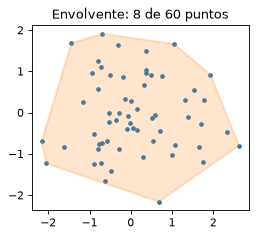

In [4]:
def vertices_fuerza_bruta(puntos):
    puntos = list(set(puntos))
    vertices = set()
    for p in puntos:
        resto = [q for q in puntos if q != p]
        en_lado = any(en_segmento(p, a, b) for a, b in combinations(resto, 2))
        en_triangulo = any(
            len({orientacion(a, b, p), orientacion(b, c, p), orientacion(c, a, p)} - {0}) == 1 and orientacion(a, b, c) != 0
            for a, b, c in combinations(resto, 3)
        )
        if not en_lado and not en_triangulo:
            vertices.add(p)
    return vertices


rng = np.random.default_rng(3)
for prueba in range(300):
    puntos = [tuple(map(int, p)) for p in rng.integers(0, 8, size=(rng.integers(3, 30), 2))]
    g, a = graham(puntos), andrew(puntos)
    assert mismo_ciclo(g, a)
    distintos = np.array(sorted(set(puntos)))
    if len(g) >= 3:
        hull = ConvexHull(distintos)
        assert set(g) == {tuple(map(int, distintos[i])) for i in hull.vertices}
        assert np.isclose(hull.volume, float(area_con_signo(g)))
    if prueba < 60:
        assert set(g) == vertices_fuerza_bruta(puntos) or len(g) < 3
print("Graham, Andrew, scipy y fuerza bruta coinciden en 300 nubes")

puntos = rng.normal(size=(60, 2)).round(2)
envolvente = andrew([tuple(p) for p in puntos])
fig, ax = plt.subplots(figsize=(4, 3))
ax.scatter(*puntos.T, s=10)
ax.fill(*zip(*envolvente), alpha=0.2, edgecolor="C1", lw=2)
ax.set_aspect("equal")
ax.set_title(f"Envolvente: {len(envolvente)} de {len(puntos)} puntos")
plt.show()

## 4. Punto en un polígono convexo en $O(\log n)$

En un polígono convexo en sentido antihorario $v_0, \dots, v_{n-1}$, las diagonales desde $v_0$ lo dividen en un abanico de triángulos ordenados por ángulo. Escribir `dentro_convexo(p, poligono)`, que busque con búsqueda binaria el sector $v_0 v_k v_{k+1}$ en el que cae $p$ y lo compruebe con una orientación (el borde cuenta como dentro). Compararlo con un test lineal (estar a la izquierda o sobre todas las aristas) en miles de puntos.

In [5]:
def dentro_convexo(p, poligono):
    v0, n = poligono[0], len(poligono)
    if orientacion(v0, poligono[1], p) < 0 or orientacion(v0, poligono[-1], p) > 0:
        return False
    lo, hi = 1, n - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if orientacion(v0, poligono[mid], p) >= 0:
            lo = mid
        else:
            hi = mid
    return orientacion(poligono[lo], poligono[lo + 1], p) >= 0


def dentro_convexo_lineal(p, poligono):
    return all(orientacion(a, b, p) >= 0 for a, b in pairwise(poligono + poligono[:1]))


rng = random.Random(4)
for _ in range(50):
    poligono = andrew([(rng.randint(-20, 20), rng.randint(-20, 20)) for _ in range(25)])
    for _ in range(200):
        p = (rng.randint(-22, 22), rng.randint(-22, 22))
        assert dentro_convexo(p, poligono) == dentro_convexo_lineal(p, poligono), (p, poligono)
print("Búsqueda binaria y test lineal coinciden en 10 000 puntos")

Búsqueda binaria y test lineal coinciden en 10 000 puntos


## 5. Diámetro con calibres rotatorios

El par de puntos más alejado de una nube está siempre entre los vértices de su envolvente. Escribir `diametro(puntos)` con calibres rotatorios: para cada arista $v_i v_{i+1}$ se avanza un segundo índice $j$ mientras el triángulo $v_i v_{i+1} v_{j+1}$ tenga más área que $v_i v_{i+1} v_j$ (el punto más alejado de la arista), y se comparan las distancias de $v_j$ a los dos extremos. Así se recorre todo en $O(h)$ tras la envolvente. Compararlo con todas las parejas.

In [6]:
def diametro(puntos):
    h = andrew(puntos)
    if len(h) < 3:
        return max((dist2(p, q), p, q) for p, q in combinations(h, 2)) if len(h) == 2 else (0, h[0], h[0])
    n, j, mejor = len(h), 1, (0, None, None)
    for i in range(n):
        a, b = h[i], h[(i + 1) % n]
        while abs(cruz(a, b, h[(j + 1) % n])) > abs(cruz(a, b, h[j])):
            j = (j + 1) % n
        mejor = max(mejor, (dist2(a, h[j]), a, h[j]), (dist2(b, h[j]), b, h[j]))
    return mejor


rng = random.Random(5)
for _ in range(300):
    puntos = list({(rng.randint(0, 30), rng.randint(0, 30)) for _ in range(rng.randint(2, 40))})
    assert diametro(puntos)[0] == max(dist2(p, q) for p, q in combinations(puntos, 2))
d2, p, q = diametro(nube)
print(f"Diámetro de la nube: {p}–{q}, √{d2} ≈ {math.sqrt(d2):.3f}")

Diámetro de la nube: (4, 4)–(0, 0), √32 ≈ 5.657


## 6. Par más cercano con un barrido

Ordenar los puntos por $x$ y recorrerlos manteniendo una franja activa, ordenada por $y$, con los puntos cuya $x$ está a menos de la mejor distancia $d$ encontrada. Para cada punto nuevo basta mirar en la franja los que tienen $y$ en $[y - d, y + d]$ (se localizan con `bisect`), que son pocos. Escribir `cercanos_barrido(puntos)`, devolviendo el cuadrado de la distancia y el par, y compararlo con la fuerza bruta.

In [7]:
def cercanos_barrido(puntos):
    puntos = sorted(puntos)
    mejor = (math.inf, None, None)
    franja, izquierda = [], 0
    for p in puntos:
        d = math.sqrt(mejor[0])
        while izquierda < len(puntos) and puntos[izquierda][0] < p[0] - d:
            q = puntos[izquierda]
            franja.pop(bisect_left(franja, (q[1], q[0])))
            izquierda += 1
        desde = bisect_left(franja, (p[1] - d, -math.inf))
        hasta = bisect_right(franja, (p[1] + d, math.inf))
        for y, x in franja[desde:hasta]:
            mejor = min(mejor, (dist2(p, (x, y)), (x, y), p))
        insort(franja, (p[1], p[0]))
    return mejor


def cercanos_fuerza_bruta(puntos):
    return min(dist2(p, q) for p, q in combinations(puntos, 2))


rng = random.Random(6)
for _ in range(300):
    puntos = [(rng.randint(0, 1000), rng.randint(0, 1000)) for _ in range(rng.randint(2, 60))]
    assert cercanos_barrido(puntos)[0] == cercanos_fuerza_bruta(puntos)
d2, p, q = cercanos_barrido([(rng.randint(0, 10**6), rng.randint(0, 10**6)) for _ in range(20_000)])
print(f"20 000 puntos: el par más cercano es {p}–{q}, a {math.sqrt(d2):.1f}")

20 000 puntos: el par más cercano es (372508, 562894)–(372512, 562943), a 49.2


## 7. Par más cercano con una rejilla aleatoria

Otra idea, de tiempo esperado $O(n)$: barajar los puntos e ir añadiéndolos a una rejilla de celdas de lado $d$ (la mejor distancia hasta el momento). Un punto nuevo solo puede estar más cerca que $d$ de los puntos de las 9 celdas que lo rodean; si lo está, $d$ disminuye y se reconstruye la rejilla con los puntos ya vistos. Como el orden es aleatorio, la probabilidad de reconstruir en el paso $i$ es como mucho $2/i$, así que el número esperado de reconstrucciones es del orden de $2H_n \approx 2 \ln n$. Escribir `cercanos_rejilla(puntos, semilla)`, comparar el resultado con el barrido y contar las reconstrucciones medias con varias semillas.

In [8]:
def cercanos_rejilla(puntos, semilla=0):
    puntos = list(puntos)
    random.Random(semilla).shuffle(puntos)
    mejor = (dist2(puntos[0], puntos[1]), puntos[0], puntos[1])
    reconstrucciones = 0

    def construir(hasta):
        lado = max(math.sqrt(mejor[0]), 1e-9)
        rejilla = {}
        for p in puntos[:hasta]:
            rejilla.setdefault((int(p[0] // lado), int(p[1] // lado)), []).append(p)
        return lado, rejilla

    lado, rejilla = construir(2)
    for i in range(2, len(puntos)):
        p = puntos[i]
        cx, cy = int(p[0] // lado), int(p[1] // lado)
        candidatos = [q for dx in (-1, 0, 1) for dy in (-1, 0, 1) for q in rejilla.get((cx + dx, cy + dy), ())]
        vecino = min(((dist2(p, q), q, p) for q in candidatos), default=(math.inf, None, None))
        if vecino[0] < mejor[0]:
            mejor = vecino
            if mejor[0] == 0:
                break
            reconstrucciones += 1
            lado, rejilla = construir(i + 1)
        else:
            rejilla.setdefault((cx, cy), []).append(p)
    return mejor, reconstrucciones


rng = random.Random(7)
for _ in range(300):
    puntos = list({(rng.randint(0, 1000), rng.randint(0, 1000)) for _ in range(rng.randint(2, 60))})
    if len(puntos) >= 2:
        assert cercanos_rejilla(puntos, semilla=len(puntos))[0][0] == cercanos_fuerza_bruta(puntos)

print(f"{'n':>6} {'reconstrucciones (media)':>25} {'2·Hₙ':>6}")
for n in [100, 1_000, 10_000]:
    medias = []
    for semilla in range(10):
        puntos = list({(rng.randint(0, 10**7), rng.randint(0, 10**7)) for _ in range(n)})
        (d2, _, _), r = cercanos_rejilla(puntos, semilla=semilla)
        assert d2 == cercanos_barrido(puntos)[0]
        medias.append(r)
    print(f"{n:>6} {sum(medias) / len(medias):>25.1f} {2 * sum(1 / i for i in range(1, n + 1)):>6.1f}")

     n  reconstrucciones (media)   2·Hₙ
   100                       7.8   10.4
  1000                      12.5   15.0


 10000                      14.7   19.6


## 8. Barrido para encontrar todos los cruces

Para encontrar todas las parejas de segmentos que se cortan, la fuerza bruta prueba las $\binom{n}{2}$ parejas. Un barrido con una recta vertical solo necesita comparar segmentos cuyas proyecciones sobre el eje $x$ se solapan: se ordenan los extremos como eventos, se mantiene el conjunto de segmentos activos y cada segmento que entra se compara solo con los activos. Escribir `cruces_barrido(segmentos)`, devolviendo los pares y el número de comparaciones, y comprobar que encuentra los mismos pares que la fuerza bruta con segmentos cortos.

In [9]:
def cruces_barrido(segmentos):
    eventos = []
    for i, (p, q) in enumerate(segmentos):
        eventos += [(min(p[0], q[0]), 0, i), (max(p[0], q[0]), 1, i)]
    eventos.sort()
    activos, pares, comparaciones = set(), set(), 0
    for _, tipo, i in eventos:
        if tipo == 1:
            activos.discard(i)
            continue
        for j in activos:
            comparaciones += 1
            if se_cortan(*segmentos[i], *segmentos[j]):
                pares.add((min(i, j), max(i, j)))
        activos.add(i)
    return pares, comparaciones


def segmentos_aleatorios(n, largo, rng, tam=1000):
    resultado = []
    for _ in range(n):
        x, y = rng.randint(0, tam), rng.randint(0, tam)
        resultado.append(((x, y), (x + rng.randint(-largo, largo), y + rng.randint(-largo, largo))))
    return resultado


rng = random.Random(8)
print(f"{'n':>5} {'cruces':>7} {'comparaciones':>14} {'fuerza bruta':>13}")
for n in [50, 200, 800]:
    segmentos = segmentos_aleatorios(n, 40, rng)
    pares, comparaciones = cruces_barrido(segmentos)
    fuerza = {(i, j) for i, j in combinations(range(n), 2) if se_cortan(*segmentos[i], *segmentos[j])}
    assert pares == fuerza
    print(f"{n:>5} {len(pares):>7} {comparaciones:>14} {n * (n - 1) // 2:>13}")

    n  cruces  comparaciones  fuerza bruta
   50       0             48          1225
  200      10            837         19900


  800     187          13024        319600


## 9. Algoritmo de Shamos-Hoey

Si solo se quiere saber si hay algún cruce, basta con mantener los segmentos activos ordenados por la altura a la que los corta la recta de barrido y comparar cada segmento solo con sus vecinos de arriba y de abajo: al insertarlo, con sus dos vecinos, y al quitarlo, sus dos vecinos entre sí. Mientras no haya cruces el orden vertical no cambia, y el primer cruce aparece entre dos segmentos que en algún momento fueron vecinos. Escribir `hay_cruce(segmentos)` (con segmentos no verticales en posición general) y compararlo con la fuerza bruta en muchos conjuntos pequeños, la mitad con cruces y la mitad sin ellos.

In [10]:
def altura(segmento, x):
    (x0, y0), (x1, y1) = segmento
    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)


def hay_cruce(segmentos):
    segmentos = [tuple(sorted(s)) for s in segmentos]
    eventos = sorted([(s[0][0], 0, i) for i, s in enumerate(segmentos)] + [(s[1][0], 1, i) for i, s in enumerate(segmentos)])
    activos = []

    def cortan(i, j):
        return se_cortan(*segmentos[i], *segmentos[j])

    for x, tipo, i in eventos:
        if tipo == 0:
            alturas = [altura(segmentos[j], x) for j in activos]
            pos = bisect_left(alturas, segmentos[i][0][1])
            activos.insert(pos, i)
            for v in (pos - 1, pos + 1):
                if 0 <= v < len(activos) and cortan(i, activos[v]):
                    return segmentos[i], segmentos[activos[v]]
        else:
            pos = activos.index(i)
            if 0 < pos < len(activos) - 1 and cortan(activos[pos - 1], activos[pos + 1]):
                return segmentos[activos[pos - 1]], segmentos[activos[pos + 1]]
            activos.pop(pos)
    return None


rng = random.Random(9)
resultados = {True: 0, False: 0}
for _ in range(4000):
    n = rng.randint(2, 7)
    segmentos = [((rng.random(), rng.random()), (rng.random(), rng.random())) for _ in range(n)]
    esperado = any(se_cortan(*a, *b) for a, b in combinations(segmentos, 2))
    encontrado = hay_cruce(segmentos)
    assert (encontrado is not None) == esperado
    if encontrado:
        assert se_cortan(*encontrado[0], *encontrado[1])
    resultados[esperado] += 1
print("Conjuntos con cruce:", resultados[True], "| sin cruce:", resultados[False])

Conjuntos con cruce: 2863 | sin cruce: 1137


## 10. Intersección de dos polígonos convexos

Recortar un polígono convexo con otro (algoritmo de Sutherland-Hodgman): para cada arista del polígono que recorta, quedarse con la parte del otro que está a su izquierda, añadiendo los puntos de corte. Con coordenadas enteras y `Fraction`, el resultado es exacto. Escribir `recortar(sujeto, recorte)` y comprobar que el área de la intersección no depende del orden, que nunca supera la de ninguno de los dos y que coincide con una estimación de Monte Carlo con `numpy`. Dibujar un ejemplo.

Intersección: [('3', '3/10'), ('10', '1'), ('25/4', '6'), ('3', '6')]
Área: 1123/40


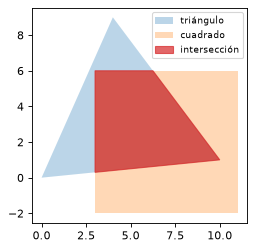

In [11]:
def corte_rectas(p, q, a, b):
    """Punto donde el segmento pq corta la recta ab."""
    cp, cq = cruz(a, b, p), cruz(a, b, q)
    t = Fraction(cp, cp - cq)
    return (p[0] + t * (q[0] - p[0]), p[1] + t * (q[1] - p[1]))


def recortar(sujeto, recorte):
    resultado = list(sujeto)
    for a, b in pairwise(recorte + recorte[:1]):
        entrada, resultado = resultado, []
        for p, q in pairwise(entrada + entrada[:1]):
            dentro_p, dentro_q = cruz(a, b, p) >= 0, cruz(a, b, q) >= 0
            if dentro_p:
                resultado.append(p)
            if dentro_p != dentro_q:
                resultado.append(corte_rectas(p, q, a, b))
        if not resultado:
            return []
    return resultado


def dentro_todas(xs, ys, poligono):
    dentro = np.ones_like(xs, dtype=bool)
    for (ax, ay), (bx, by) in pairwise(poligono + poligono[:1]):
        dentro &= (bx - ax) * (ys - ay) - (by - ay) * (xs - ax) >= 0
    return dentro


triangulo = [(0, 0), (10, 1), (4, 9)]
cuadrado = [(3, -2), (11, -2), (11, 6), (3, 6)]
interseccion = recortar(triangulo, cuadrado)
print("Intersección:", [tuple(map(str, p)) for p in interseccion])
print("Área:", area_con_signo(interseccion))

rng = random.Random(10)
muestras = np.random.default_rng(10).uniform(-10, 10, size=(2, 200_000))
for _ in range(40):
    a = andrew([(rng.randint(-8, 8), rng.randint(-8, 8)) for _ in range(8)])
    b = andrew([(rng.randint(-8, 8), rng.randint(-8, 8)) for _ in range(8)])
    area_ab = area_con_signo(recortar(a, b)) if len(a) > 2 and len(b) > 2 else 0
    area_ba = area_con_signo(recortar(b, a)) if len(a) > 2 and len(b) > 2 else 0
    assert area_ab == area_ba and area_ab <= min(area_con_signo(a), area_con_signo(b))
    if len(a) > 2 and len(b) > 2:
        estimada = 400 * np.mean(dentro_todas(*muestras, a) & dentro_todas(*muestras, b))
        assert abs(estimada - float(area_ab)) < 1.5

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.fill(*zip(*triangulo), alpha=0.3, label="triángulo")
ax.fill(*zip(*cuadrado), alpha=0.3, label="cuadrado")
ax.fill(*zip(*[(float(x), float(y)) for x, y in interseccion]), color="C3", alpha=0.7, label="intersección")
ax.set_aspect("equal")
ax.legend(fontsize=8)
plt.show()

## 11. Círculo mínimo envolvente de Welzl

El menor círculo que contiene una nube de puntos queda determinado por dos puntos (diametralmente opuestos) o por tres de su borde. El algoritmo de Welzl, en su versión iterativa, baraja los puntos y los añade uno a uno: si el nuevo punto queda fuera, tiene que estar en el borde del nuevo círculo, y se recalcula con él fijado (y con un segundo punto fijado si hace falta). El tiempo esperado es $O(n)$. Escribir `circulo_minimo(puntos, semilla)` con `Fraction` (centro exacto y radio al cuadrado) y compararlo con la fuerza bruta sobre todos los círculos de dos y tres puntos.

Centro (0, 7/2), radio² = 17885/4, radio ≈ 66.867


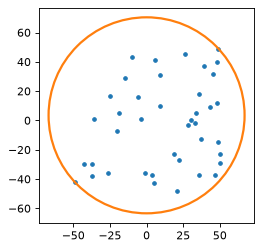

In [12]:
def circulo_dos(a, b):
    centro = (Fraction(a[0] + b[0], 2), Fraction(a[1] + b[1], 2))
    return centro, dist2(centro, a)


def circulo_tres(a, b, c):
    d = 2 * cruz(a, b, c)
    if d == 0:
        return None
    a2, b2, c2 = a[0] ** 2 + a[1] ** 2, b[0] ** 2 + b[1] ** 2, c[0] ** 2 + c[1] ** 2
    ux = Fraction(a2 * (b[1] - c[1]) + b2 * (c[1] - a[1]) + c2 * (a[1] - b[1]), d)
    uy = Fraction(a2 * (c[0] - b[0]) + b2 * (a[0] - c[0]) + c2 * (b[0] - a[0]), d)
    return (ux, uy), dist2((ux, uy), a)


def contiene(circulo, p):
    return dist2(circulo[0], p) <= circulo[1]


def circulo_minimo(puntos, semilla=0):
    puntos = [tuple(map(Fraction, p)) for p in puntos]
    random.Random(semilla).shuffle(puntos)
    c = (puntos[0], Fraction(0))
    for i, p in enumerate(puntos):
        if contiene(c, p):
            continue
        c = (p, Fraction(0))
        for j, q in enumerate(puntos[:i]):
            if contiene(c, q):
                continue
            c = circulo_dos(p, q)
            for r in puntos[:j]:
                if not contiene(c, r):
                    c = circulo_tres(p, q, r)
    return c


def circulo_minimo_fuerza_bruta(puntos):
    candidatos = [circulo_dos(a, b) for a, b in combinations(puntos, 2)]
    candidatos += [c for t in combinations(puntos, 3) if (c := circulo_tres(*t))]
    return min(c[1] for c in candidatos if all(contiene(c, p) for p in puntos))


rng = random.Random(11)
for _ in range(200):
    puntos = list({(rng.randint(-10, 10), rng.randint(-10, 10)) for _ in range(rng.randint(2, 14))})
    if len(puntos) >= 2:
        assert circulo_minimo(puntos, semilla=3)[1] == circulo_minimo_fuerza_bruta(puntos)

puntos = [tuple(p) for p in np.random.default_rng(11).integers(-50, 51, size=(40, 2)).tolist()]
(cx, cy), r2 = circulo_minimo(puntos)
print(f"Centro ({cx}, {cy}), radio² = {r2}, radio ≈ {math.sqrt(r2):.3f}")
assert all(contiene(((cx, cy), r2), p) for p in puntos)
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.scatter(*zip(*puntos), s=10)
ax.add_patch(plt.Circle((float(cx), float(cy)), math.sqrt(r2), fill=False, color="C1", lw=2))
ax.set_aspect("equal")
ax.autoscale()
plt.show()

## 12. Las capitales de las islas

Con las coordenadas (aproximadas) de las siete capitales insulares de Canarias, proyectadas a kilómetros con una proyección equirrectangular centrada en el archipiélago ($x = R\,\Delta\lambda \cos\varphi_0$, $y = R\,\Delta\varphi$, $R = 6371$ km), calcular: qué capitales forman la envolvente convexa y el área que encierra, la pareja más cercana y la más alejada, y el círculo mínimo que las contiene a todas (el alcance que necesitaría una antena colocada en su centro). Dibujarlo todo.

Envolvente: Valverde → Las Palmas de G. C. → Puerto del Rosario → Arrecife → Santa Cruz de La Palma
Área encerrada: 31,232 km²
Más cercanas: Puerto del Rosario y Arrecife, 60 km
Más alejadas: Arrecife y Valverde, 446 km
Antena en (28.386, -15.732) con un alcance de 223 km


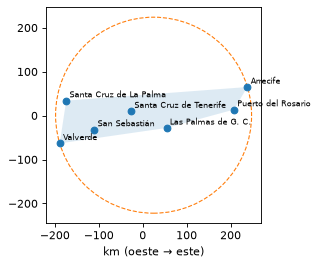

In [13]:
capitales = {
    "Santa Cruz de Tenerife": (28.468, -16.255),
    "Las Palmas de G. C.": (28.125, -15.430),
    "Arrecife": (28.963, -13.548),
    "Puerto del Rosario": (28.500, -13.863),
    "San Sebastián": (28.092, -17.110),
    "Santa Cruz de La Palma": (28.684, -17.764),
    "Valverde": (27.809, -17.915),
}
R = 6371
lat_media = sum(lat for lat, _ in capitales.values()) / len(capitales)
lon_media = sum(lon for _, lon in capitales.values()) / len(capitales)
cos0 = math.cos(math.radians(lat_media))
km = {nombre: (R * math.radians(lon - lon_media) * cos0, R * math.radians(lat - lat_media))
      for nombre, (lat, lon) in capitales.items()}
nombre_de = {p: n for n, p in km.items()}

envolvente = andrew(list(km.values()))
print("Envolvente:", " → ".join(nombre_de[p] for p in envolvente))
print(f"Área encerrada: {float(area_con_signo(envolvente)):,.0f} km²")

d2, p, q = cercanos_barrido(list(km.values()))
assert d2 == cercanos_fuerza_bruta(list(km.values()))
print(f"Más cercanas: {nombre_de[p]} y {nombre_de[q]}, {math.sqrt(d2):.0f} km")
d2, p, q = diametro(list(km.values()))
print(f"Más alejadas: {nombre_de[p]} y {nombre_de[q]}, {math.sqrt(d2):.0f} km")

(cx, cy), r2 = circulo_minimo(list(km.values()))
cx, cy, radio = float(cx), float(cy), math.sqrt(r2)
lat_c = lat_media + math.degrees(cy / R)
lon_c = lon_media + math.degrees(cx / (R * cos0))
print(f"Antena en ({lat_c:.3f}, {lon_c:.3f}) con un alcance de {radio:.0f} km")
assert 2 * radio >= math.sqrt(d2) - 1e-9 and all(math.dist((cx, cy), p) <= radio + 1e-9 for p in km.values())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.fill(*zip(*envolvente), alpha=0.15)
ax.add_patch(plt.Circle((cx, cy), radio, fill=False, ls="--", color="C1"))
for nombre, (x, y) in km.items():
    ax.plot(x, y, "o", color="C0")
    ax.annotate(nombre, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_aspect("equal")
ax.autoscale()
ax.set_xlabel("km (oeste → este)")
plt.show()